# SmartCart Clustering System

In [1]:
import pandas as pd 
import seaborn as sns 
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans
from kneed import KneeLocator
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

import numpy as np
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

In [2]:
data = pd.read_csv("smartcart_customers.csv")
df=data.drop("ID",axis=1)


In [3]:
# Data Preprocessing 
df["Income"]=df["Income"].fillna(df["Income"].median())

In [4]:
# when we have date in data we need to convert to numerical values to get max accuracy 

df["Age"]=2026-df["Year_Birth"]
# feature engineering convert date values to numerical 
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
refDate =df["Dt_Customer"].max()
df["Customer_Tenure_Date"]=(refDate-df["Dt_Customer"]).dt.days
# Total Spending Feature 
df.columns
df["Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]
# Total Children 
df["TotalChild"]=df["Kidhome"]+df["Teenhome"]
# Education 
df["Education"].value_counts()

# we have 5 values we convert it to 3 (undergraduate,graduate,postgraduate)
df["Education"]=df["Education"].replace(
    {
        "Basic":"Undergraduate",
        "2n Cycle":"Undergraduate",
        "Graduation":"Graduate",
        "Master":"Postgraduate",
        "PhD":"Postgraduate"
    }
)
df["Marital_Status"].value_counts()

df["Living_With"]=df["Marital_Status"].replace(
    {
        "Married":"Partner",
        "Together":"Partner",
        "Single":"Alone",
        "YOLO":"Alone",
        "Widow":"Alone",
        "Absurd":"Alone",
        "Divorced":"Alone"
    }
)

In [5]:
# now we have created neccessary features we drop unnecesary columns 

cols=["Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer","MntFruits","MntWines","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
df_cleaned=df.drop(cols,axis=1)


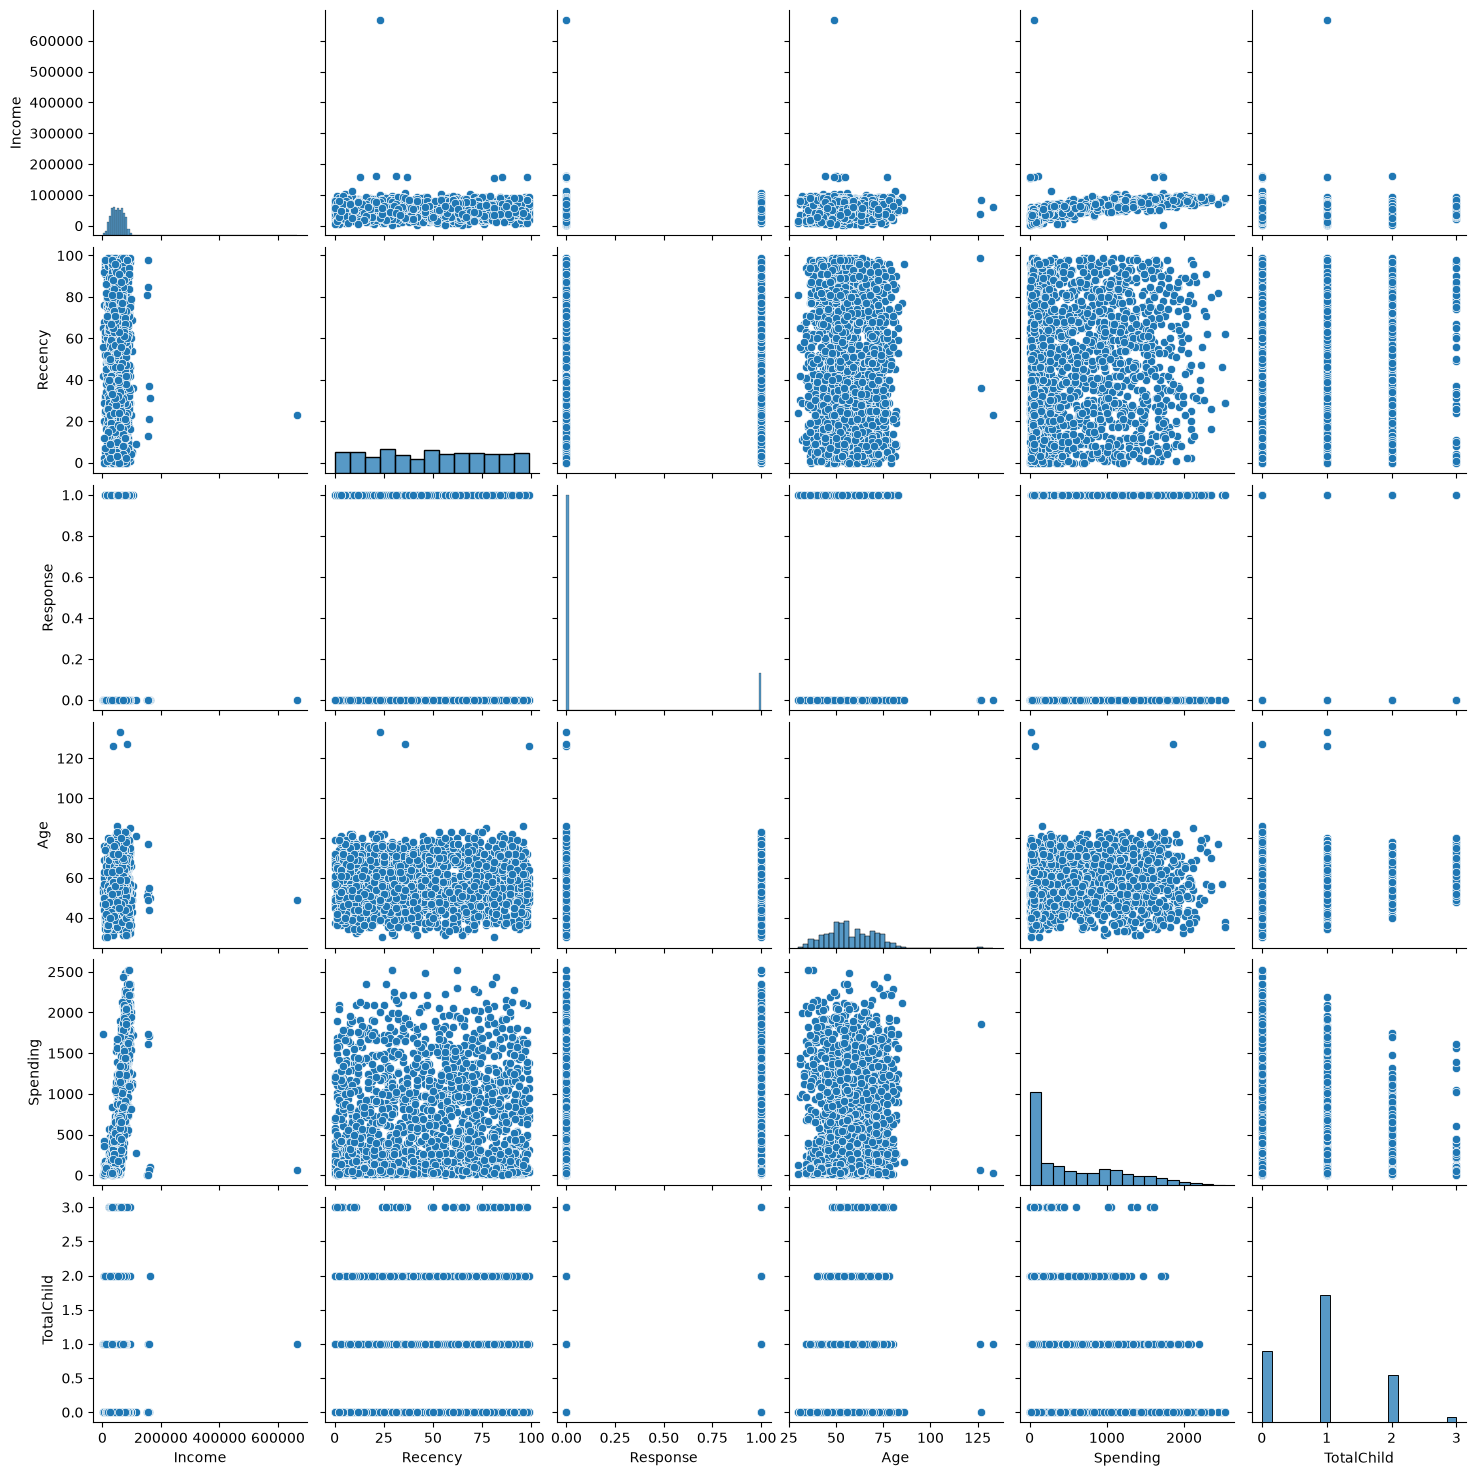

In [6]:
# Handling Outliers 
cols=["Income","Recency","Response","Age","Spending","TotalChild"]


# Plotting 
sns.pairplot(df_cleaned[cols])

In [7]:
# Outliers are Income around 6000000, age = 120 
# remove outliers 
df_cleaned=df_cleaned[df_cleaned["Age"]<90]
df_cleaned=df_cleaned[df_cleaned["Income"]<600000]

<Axes: >

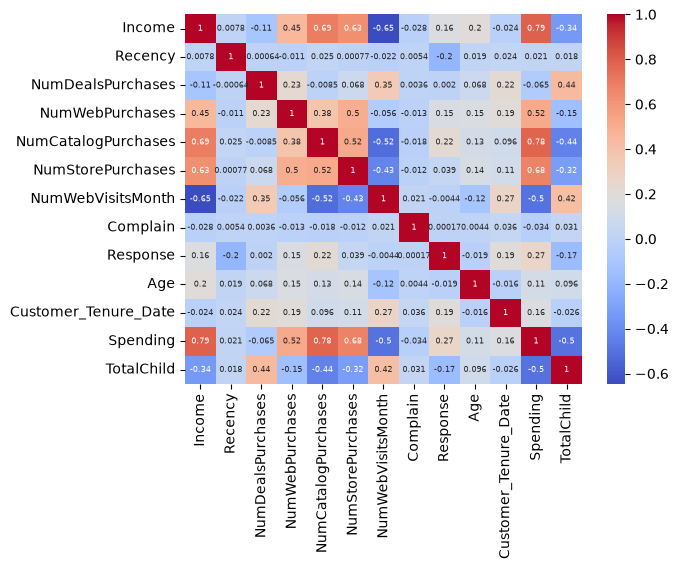

In [8]:
# Identify corelation 
corrm=df_cleaned.corr(numeric_only=True)


sns.heatmap(corrm,cmap="coolwarm",annot_kws={"size":6},annot=True)

In [9]:
# catalog purchase to income , income to total spending , income to store purchases , high income to web visits are less,Spending to catalog , Spending to store purchases 

In [10]:
categorical_cols=["Living_With","Education"]

encoder = OneHotEncoder()
enc_cols=encoder.fit_transform(df_cleaned[categorical_cols])
enc_Df=pd.DataFrame(enc_cols.toarray(),columns=encoder.get_feature_names_out(categorical_cols),index=df_cleaned.index)


In [11]:
df_encoded=pd.concat([df_cleaned.drop(columns=categorical_cols),enc_Df],axis=1)
X=df_encoded

In [12]:
scaler = StandardScaler()
X_scaled=scaler.fit_transform(X)


In [13]:
X_scaled.shape

(2236, 18)

## PCA

PCA is fit on all components first, so we can see how much variance each one carries before deciding how many to keep. The clustering space keeps enough components to retain **90 % of the variance**.

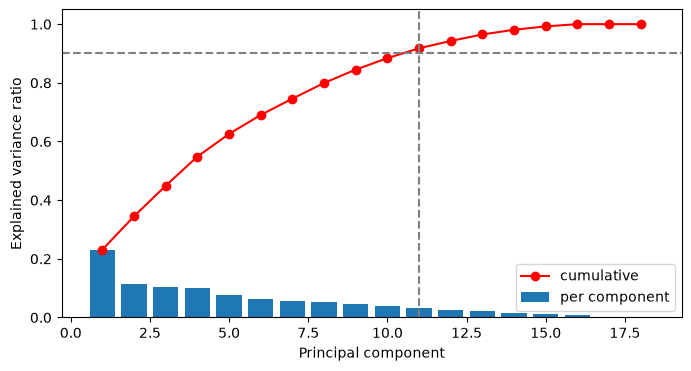

First 3 components explain 45.0% of the variance
11 components are needed to retain 90% (91.8%)


In [14]:
pca_full = PCA(random_state=42).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.90)) + 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, label="per component")
ax.plot(range(1, len(cum_var) + 1), cum_var, marker="o", color="red", label="cumulative")
ax.axhline(0.90, ls="--", color="grey")
ax.axvline(n_comp, ls="--", color="grey")
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio"); ax.legend()
plt.show()

print(f"First 3 components explain {cum_var[2]:.1%} of the variance")
print(f"{n_comp} components are needed to retain 90% ({cum_var[n_comp-1]:.1%})")

pca = PCA(n_components=n_comp, random_state=42)
pca_x = pca.fit_transform(X_scaled)     # clustering space (90% of variance)
pca_vis = pca_x[:, :3]                  # first 3 PCs, plotting only
var3 = pca.explained_variance_ratio_[:3]

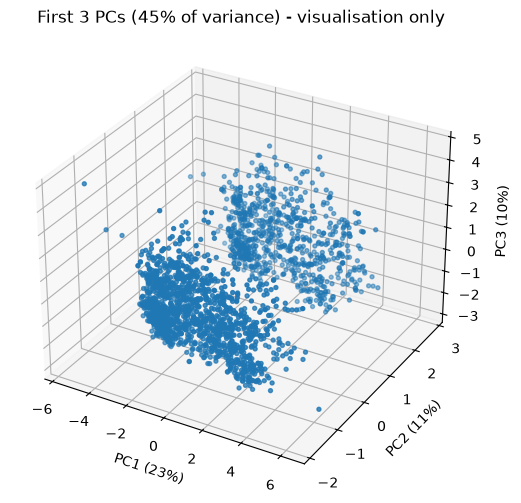

In [ ]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pca_vis[:, 0], pca_vis[:, 1], pca_vis[:, 2], s=8)
ax.set_xlabel(f"PC1 ({var3[0]:.0%})"); ax.set_ylabel(f"PC2 ({var3[1]:.0%})"); ax.set_zlabel(f"PC3 ({var3[2]:.0%})")
ax.set_title(f"First 3 PCs ({var3.sum():.0%} of variance)")
plt.show()

## Choosing K

In [16]:
k_all = list(range(1, 11))          # elbow needs K=1
k_range = list(range(2, 11))        # silhouette / CH / DB need K>=2

wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(pca_x).inertia_ for k in k_all]
knee = KneeLocator(k_all, wcss, curve="convex", direction="decreasing")
knee_k = knee.knee

sil, dbi, chi, stab = [], [], [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(pca_x)
    sil.append(silhouette_score(pca_x, km.labels_))
    dbi.append(davies_bouldin_score(pca_x, km.labels_))
    chi.append(calinski_harabasz_score(pca_x, km.labels_))
    runs = [KMeans(n_clusters=k, random_state=s, n_init=1).fit_predict(pca_x) for s in range(1, 11)]
    stab.append(np.mean([adjusted_rand_score(km.labels_, r) for r in runs]))

k_table = pd.DataFrame({"K": k_range, "silhouette": sil, "davies_bouldin": dbi,
                        "calinski_harabasz": chi, "seed_stability_ARI": stab}).round(3)
print("KneeLocator elbow K =", knee_k)
k_table

KneeLocator elbow K = 6


,K,silhouette,davies_bouldin,calinski_harabasz,seed_stability_ARI
0,2,0.197,1.912,555.051,0.997
1,3,0.161,1.999,413.092,0.576
2,4,0.161,2.139,353.361,0.571
3,5,0.157,2.013,320.114,0.656
4,6,0.181,1.712,330.383,0.488
5,7,0.179,1.650,321.380,0.522
6,8,0.171,1.614,308.362,0.611
7,9,0.177,1.550,300.724,0.592
8,10,0.183,1.623,291.286,0.657


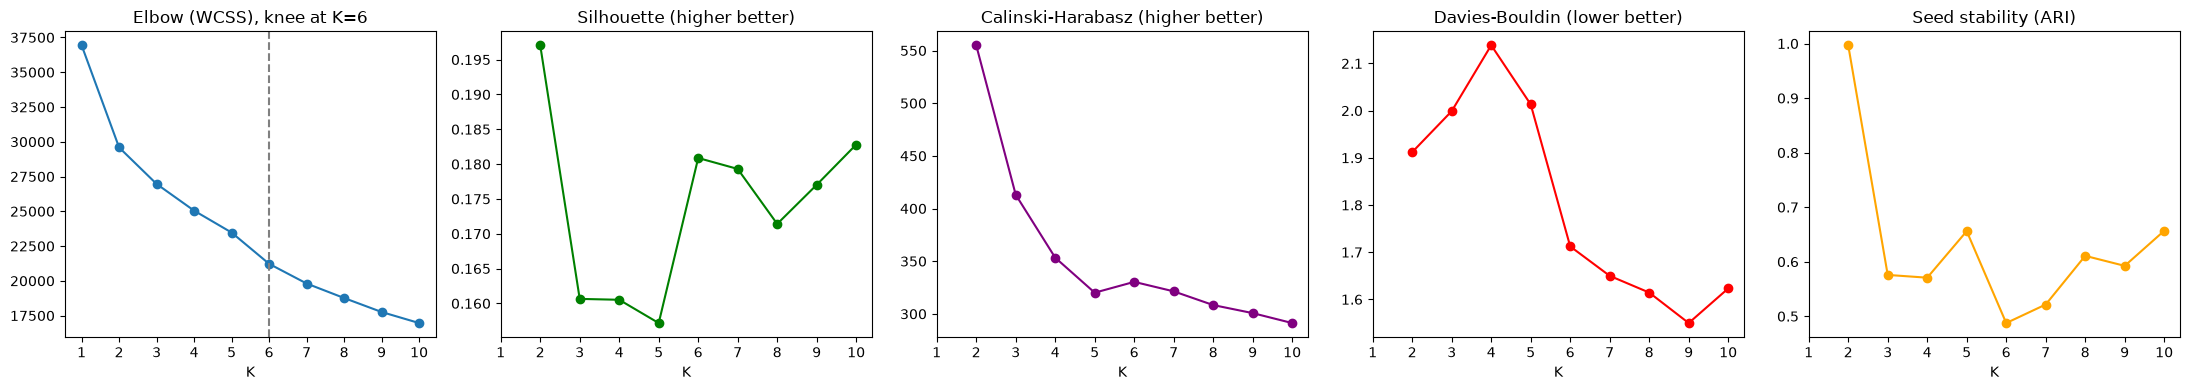

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].plot(k_all, wcss, marker="o"); axes[0].axvline(knee_k, ls="--", color="grey")
axes[0].set_title(f"Elbow (WCSS), knee at K={knee_k}")
axes[1].plot(k_range, sil, marker="o", color="green"); axes[1].set_title("Silhouette (higher better)")
axes[2].plot(k_range, chi, marker="o", color="purple"); axes[2].set_title("Calinski-Harabasz (higher better)")
axes[3].plot(k_range, dbi, marker="o", color="red"); axes[3].set_title("Davies-Bouldin (lower better)")
axes[4].plot(k_range, stab, marker="o", color="orange"); axes[4].set_title("Seed stability (ARI)")
for a in axes: a.set_xlabel("K"); a.set_xticks(k_all)
plt.tight_layout(); plt.show()

### Decision: K = 2

- **Silhouette and Calinski-Harabasz both peak at K = 2** (0.197 and 555); neither recovers at any larger K.
`FINAL_K` below is taken from the silhouette maximum, so the choice is reproducible.

FINAL_K = 2


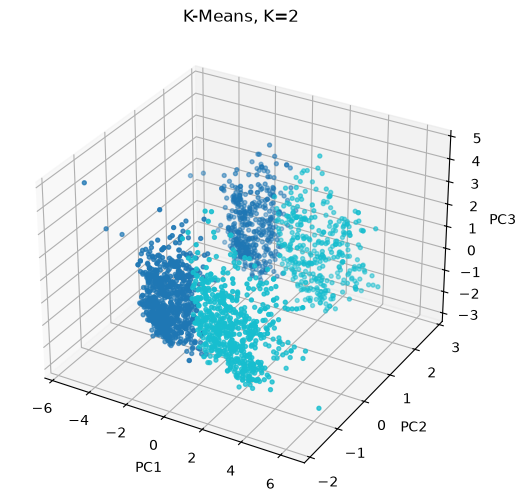

In [18]:
# K with the best silhouette; override by hand only with a reason you can state
FINAL_K = int(k_range[int(np.argmax(sil))])
print("FINAL_K =", FINAL_K)

kmm = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
labels_kmm = kmm.fit_predict(pca_x)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pca_vis[:, 0], pca_vis[:, 1], pca_vis[:, 2], c=labels_kmm, s=8, cmap="tab10")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title(f"K-Means, K={FINAL_K}")
plt.show()

## K-Means vs Agglomerative

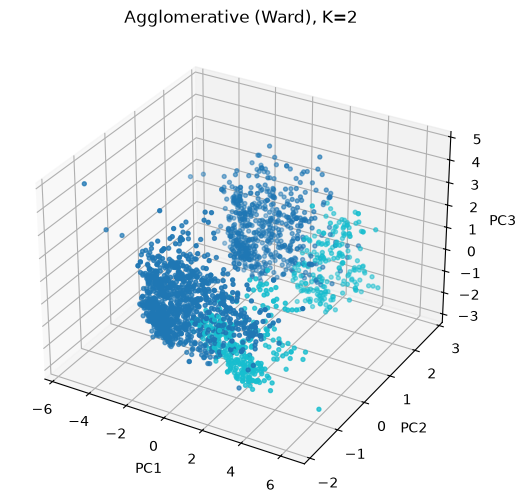

In [19]:
agc = AgglomerativeClustering(n_clusters=FINAL_K)
labels_agc = agc.fit_predict(pca_x)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pca_vis[:, 0], pca_vis[:, 1], pca_vis[:, 2], c=labels_agc, s=8, cmap="tab10")   # labels_agc, not labels_kmm
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title(f"Agglomerative (Ward), K={FINAL_K}")
plt.show()

In [20]:
def scores(labels):
    return {"silhouette": silhouette_score(pca_x, labels),
            "davies_bouldin": davies_bouldin_score(pca_x, labels),
            "calinski_harabasz": calinski_harabasz_score(pca_x, labels)}

cmp = pd.DataFrame({"KMeans": scores(labels_kmm), "Agglomerative": scores(labels_agc)}).T.round(3)
print(f"Agreement between the two label sets (ARI): {adjusted_rand_score(labels_kmm, labels_agc):.2f}")
print("Cluster sizes  KMeans:", np.bincount(labels_kmm), " Agglomerative:", np.bincount(labels_agc))
cmp

Agreement between the two label sets (ARI): 0.33
Cluster sizes  KMeans: [1262  974]  Agglomerative: [1730  506]


,silhouette,davies_bouldin,calinski_harabasz
KMeans,0.197,1.912,555.051
Agglomerative,0.138,2.087,306.569


In [21]:
# Across K, same three metrics for both methods
rows = []
for k in k_range:
    a = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(pca_x)
    b = AgglomerativeClustering(n_clusters=k).fit_predict(pca_x)
    rows.append({"K": k, "sil_KMeans": silhouette_score(pca_x, a), "sil_Agglo": silhouette_score(pca_x, b),
                 "DB_KMeans": davies_bouldin_score(pca_x, a), "DB_Agglo": davies_bouldin_score(pca_x, b),
                 "CH_KMeans": calinski_harabasz_score(pca_x, a), "CH_Agglo": calinski_harabasz_score(pca_x, b)})
pd.DataFrame(rows).round(3)

,K,sil_KMeans,sil_Agglo,DB_KMeans,DB_Agglo,CH_KMeans,CH_Agglo
0,2,0.197,0.138,1.912,2.087,555.051,306.569
1,3,0.161,0.138,1.999,2.012,413.092,265.814
2,4,0.161,0.135,2.139,2.081,353.361,265.232
3,5,0.157,0.149,2.013,1.893,320.114,267.416
4,6,0.181,0.143,1.712,1.652,330.383,277.592
5,7,0.179,0.157,1.650,1.574,321.380,267.522
6,8,0.171,0.152,1.614,1.627,308.362,261.393
7,9,0.177,0.139,1.550,1.623,300.724,257.133
8,10,0.183,0.147,1.623,1.596,291.286,249.930


### Result: K-Means is the better model here so final model is kmeans 

Final model: KMeans


<Axes: xlabel='clusters', ylabel='count'>

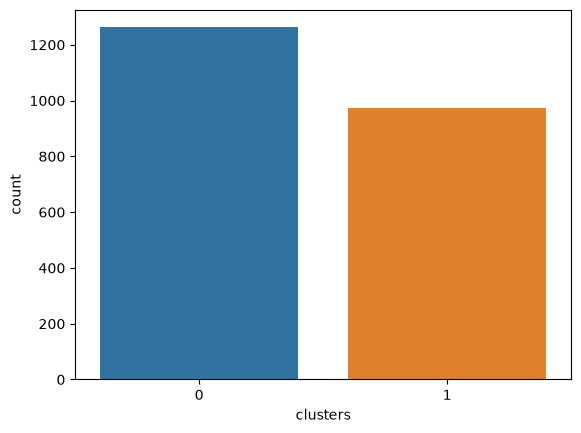

In [22]:
# Final model is whichever method scores higher on silhouette at FINAL_K
final_labels = labels_kmm if cmp.loc["KMeans", "silhouette"] >= cmp.loc["Agglomerative", "silhouette"] else labels_agc
print("Final model:", "KMeans" if final_labels is labels_kmm else "Agglomerative")

profile = X.copy()                      # do not write labels back into the feature matrix
profile["clusters"] = final_labels
pal = sns.color_palette("tab10", FINAL_K)
sns.countplot(x=profile["clusters"], palette=pal, hue=profile["clusters"], legend=False)

<Axes: xlabel='Spending', ylabel='Income'>

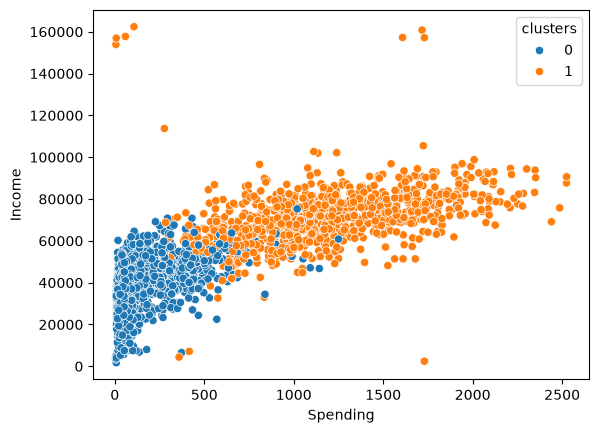

In [23]:
# income and spending patterns
sns.scatterplot(x=profile["Spending"], y=profile["Income"], hue=profile["clusters"], palette=pal)

In [24]:
profile.groupby("clusters").mean().round(2).T

clusters,0,1
Income,37363.66,70855.34
Recency,48.73,49.61
NumDealsPurchases,2.55,2.04
NumWebPurchases,2.81,5.75
NumCatalogPurchases,0.80,5.08
NumStorePurchases,3.71,8.50
NumWebVisitsMonth,6.54,3.74
Complain,0.01,0.01
Response,0.10,0.22
Age,55.46,59.23


### Cluster profiles (K-Means, K = 2)

| | Cluster 0 (n = 1262) | Cluster 1 (n = 974) |
|---|---|---|
| Income (mean) | ~37.4k | ~70.9k |
| Total spending (mean) | ~166 | ~1176 |
| Children at home | 1.27 | 0.53 |
| Web visits / month | 6.5 | 3.7 |
| Catalog / store purchases | 0.8 / 3.7 | 5.1 / 8.5 |
| Deal purchases | 2.55 | 2.04 |
| Campaign response rate | 10 % | 22 % |

- **Cluster 0 - budget, family, deal-driven.** Lower income, more children, heavy website browsing but low spend. Target with discounts, bundles and web promotions.
- **Cluster 1 - high-value, multi-channel buyers.** About 7x the spend of Cluster 0, buy through store, catalog and web, and respond to campaigns at twice the rate. Target with loyalty / premium offers and retention.
- **Recency is almost identical across clusters (48.7 vs 49.6 days)**, so these segments do not identify churn-prone customers. Churn risk needs a separate Recency-based rule applied within each cluster.
- K = 2 is the finest split this feature set supports reproducibly (see the K-selection section).